# 03 — Baselines et protocole d'évaluation
Rapport : `reports/03_baselines_report.md`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.config import load_config
cfg = load_config()
R = ROOT / "reports"; FIG = R / "figures"
def load(name): return json.loads((R / name).read_text())
def fig(name): display(Image(filename=str(FIG / name)))

## Démonstration : une prévision du naïf-24 passe par le pare-feu

In [2]:
from src.data.preprocessing import load_processed
from src.models.naive import SeasonalNaive
data = load_processed(cfg['data']['processed_dir']).asfreq('h')
o = pd.Timestamp('2010-02-01')
hist = data.loc[:o - pd.Timedelta('1h')]   # strictly before the origin
m = SeasonalNaive(24).fit(hist); display(m.predict(hist, o).head(6))

,pred,lo,hi
2010-02-01 00:00:00,0.349500,0.000000,1.098370
2010-02-01 01:00:00,0.373300,0.000000,0.965686
2010-02-01 02:00:00,0.485833,0.078153,0.941313
2010-02-01 03:00:00,0.391267,0.000741,0.765668
2010-02-01 04:00:00,0.329867,0.000000,0.730277
2010-02-01 05:00:00,0.286767,0.000000,0.772987


## Sélection (validation interne au train)

In [3]:
b = load('03_baselines_results.json')
display(pd.DataFrame(b['profile_selection']).round(4))
display(pd.DataFrame(b['sarima_selection']).sort_values('MAE').head(8).round(4))
print('SARIMA retenu :', b['sarima_best']); print('Ljung-Box :', b['sarima_residual_diagnostics'])

,weeks,stat,MAE
0,4,median,0.4420
1,4,mean,0.4434
2,6,mean,0.4455
3,6,median,0.4510
4,8,mean,0.4561
5,2,median,0.4688
6,2,mean,0.4688
7,8,median,0.4712


,order,seasonal,transform,MAE,AIC,coverage_80,seconds
0,"(1, 0, 1)","(0, 1, 1)",none,0.4672,1436.9388,0.7294,17.9
1,"(2, 0, 0)","(0, 1, 1)",none,0.4673,1437.2491,0.7280,17.4
2,"(2, 0, 1)","(0, 1, 1)",none,0.4674,1437.6583,0.7289,20.1
3,"(1, 0, 0)","(0, 1, 1)",none,0.4677,1436.4660,0.7280,16.8
4,"(1, 0, 1)","(0, 1, 1)",log,0.4731,1949.3575,0.8141,17.7
5,"(2, 0, 1)","(0, 1, 1)",log,0.4731,1949.4210,0.8141,24.6
6,"(2, 0, 0)","(0, 1, 1)",log,0.4731,1949.4408,0.8141,18.6
7,"(1, 0, 0)","(0, 1, 1)",log,0.4732,1947.7095,0.8136,16.4


SARIMA retenu : {'order': '(1, 0, 1)', 'seasonal': '(0, 1, 1)', 'transform': 'none'}
Ljung-Box : {'ljungbox_p_lag24': 0.9709016165451324, 'ljungbox_p_lag48': 0.5844275960304347, 'ljungbox_p_lag168': 0.5617092148680998}


## Résultats sur le dev-set

,MAE,MAE_ci_low,MAE_ci_high,MASE,dMAE_vs_naive24,coverage_80,width_80
naive_24,0.6474,0.6025,0.6917,0.9768,0.0000,0.7877,1.8655
naive_168,0.6197,0.5735,0.6681,0.9351,-0.0276,0.7662,1.7470
profile_4w_median,0.5168,0.4740,0.5639,0.7798,-0.1305,0.7541,1.5370
"sarima(1, 0, 1)(0, 1, 1)_24_none",0.4915,0.4596,0.5254,0.7417,-0.1558,0.8291,1.6822


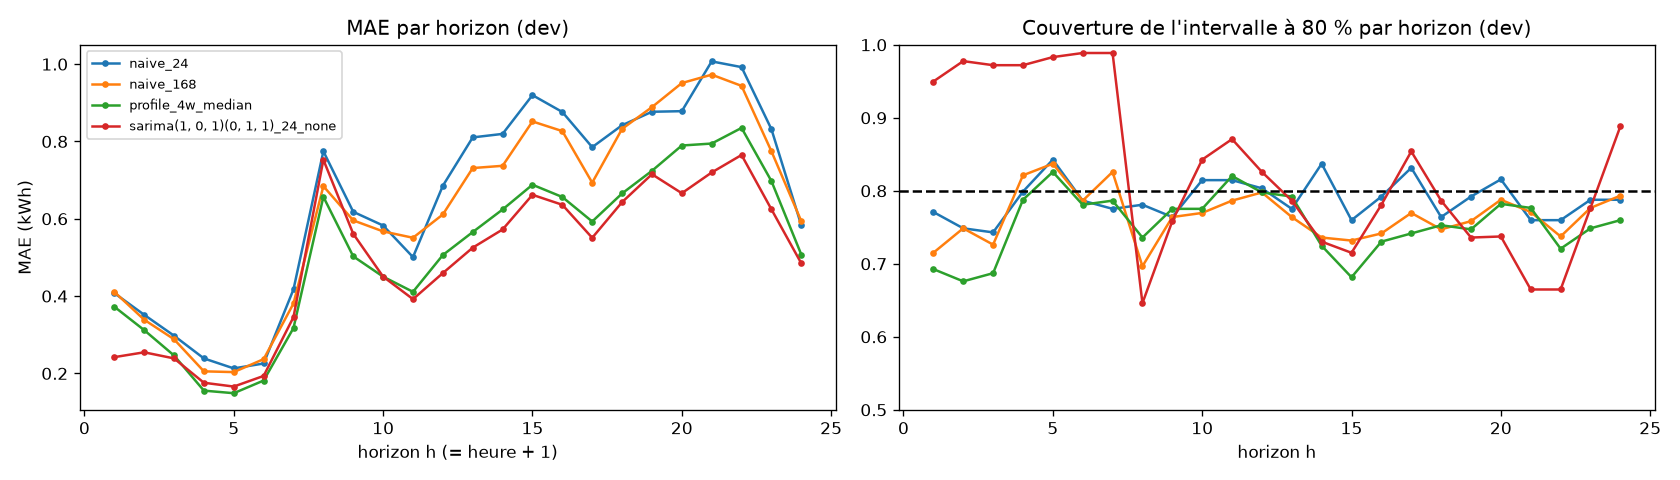

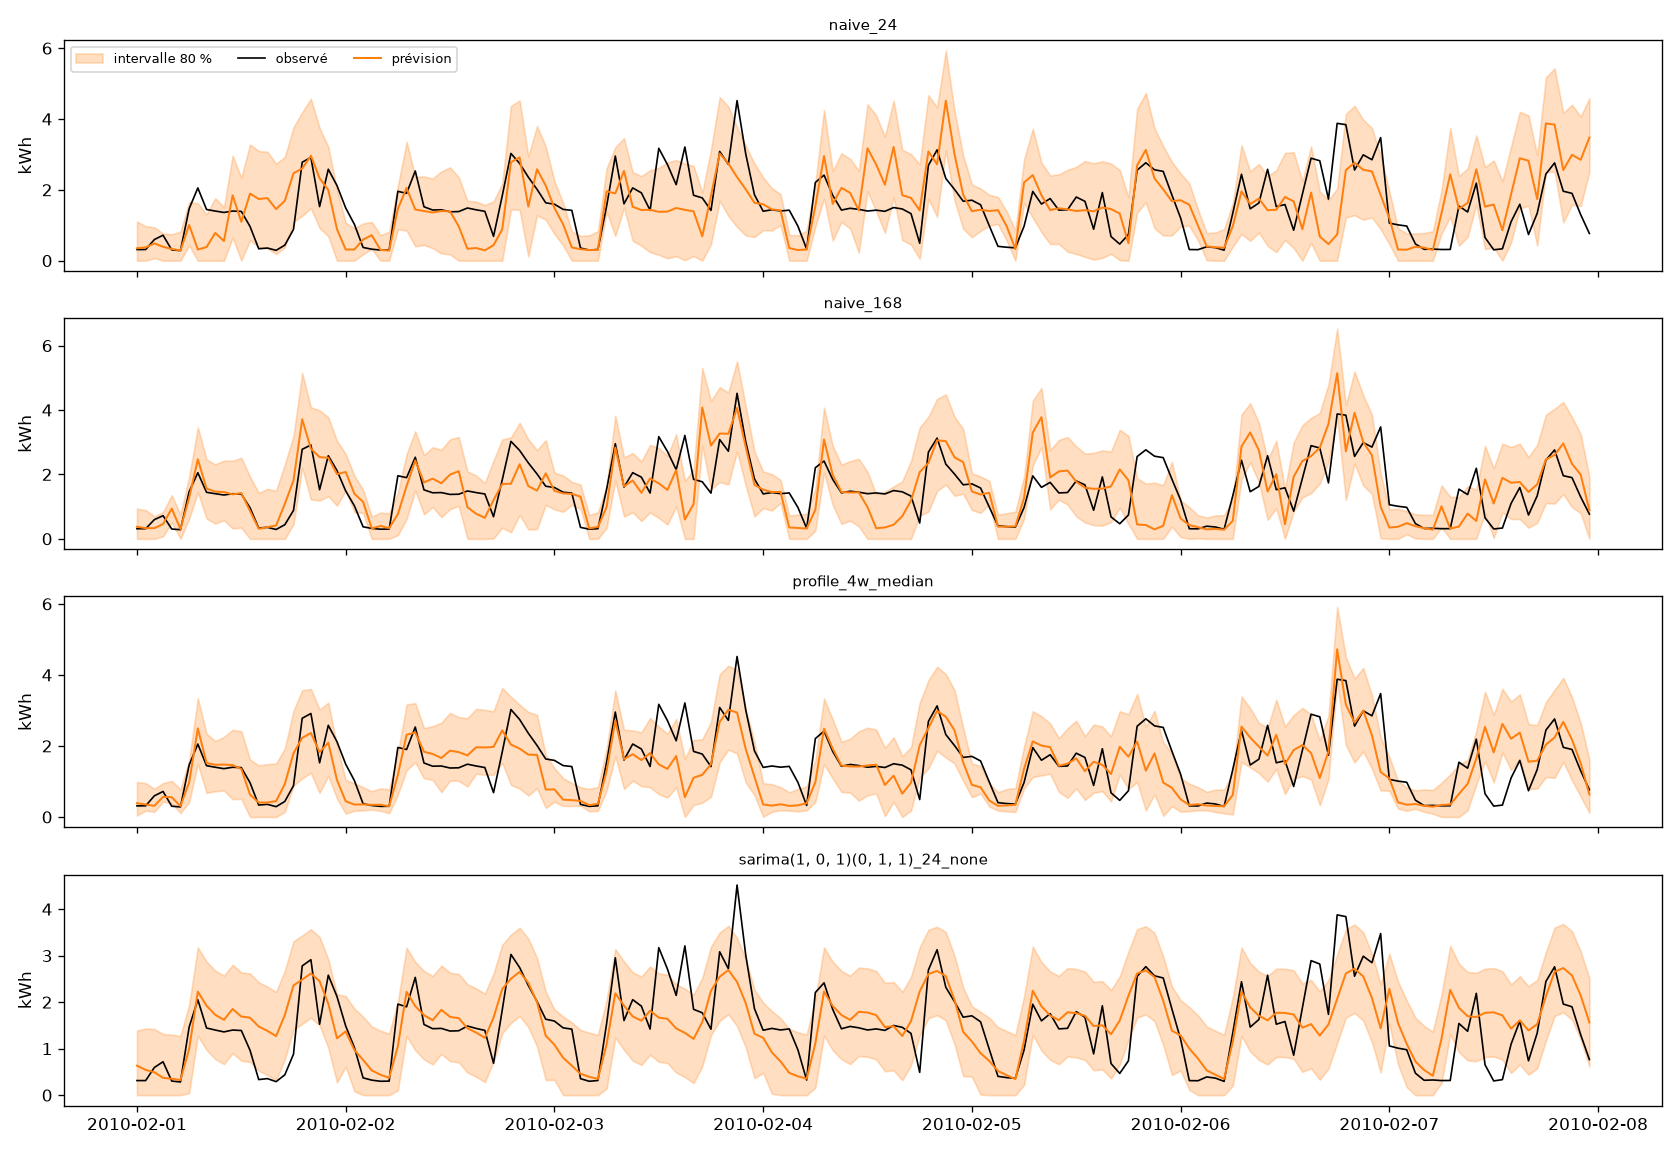

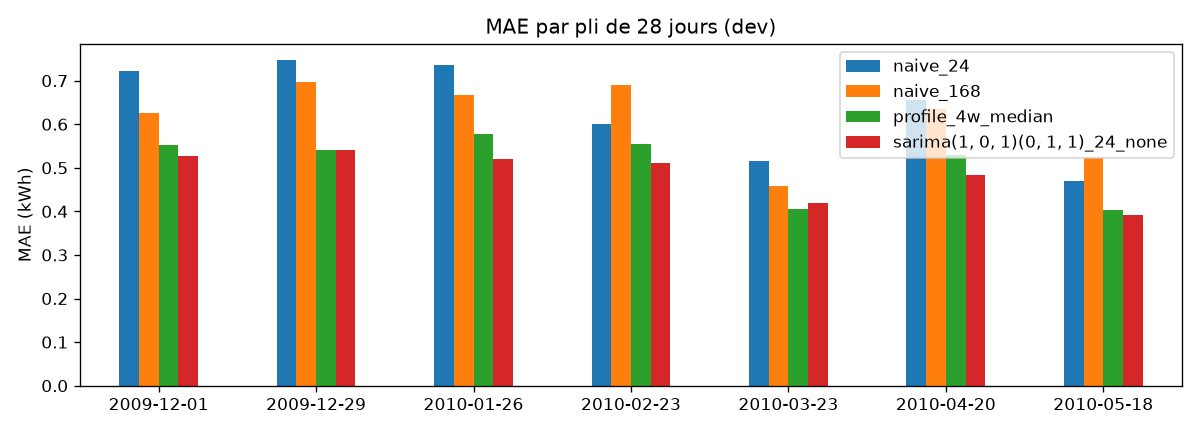

In [4]:
t = pd.DataFrame(b['dev_table']).T
display(t[['MAE','MAE_ci_low','MAE_ci_high','MASE','dMAE_vs_naive24','coverage_80','width_80']].round(4))
fig('03_mae_coverage_by_horizon.png'); fig('03_example_week.png'); fig('03_mae_by_fold.png')